# Does a policy cloned from an expert solve new games in a closed loop?

| | |
| --- | --- |
| **Question** | Does a small network trained to copy an expert's moves solve unseen grid games more often than random moves when it acts in a closed loop? |
| **Requires** | CPU only. No downloads. Synthetic grid environment. About 30 seconds. |
| **Lessons used** | [1. Your first subject](../lessons/01_your_first_subject.ipynb), [9. Closed loop](../lessons/09_closed_loop.ipynb) |

## Background

In a closed loop, an agent's action changes what it observes next, so its own errors compound. Behavior cloning trains a network to copy an expert's action on each observation, using only states the expert visited. A cloned policy can therefore agree with the expert on most training frames and still fail when its own mistakes lead it into states the expert never produced. Measuring task success in the loop, rather than per-frame agreement, tests whether the copied behavior holds up.

## Hypothesis

A cloned policy that agrees with the expert on more than 90% of training frames will solve more of 20 unseen games than a policy that moves at random.

## Method

The environment is a grid game. The player (blue) must reach the goal (green). Each observation is a rendered image of the board. A greedy oracle that always moves toward the goal is the expert.

The steps are:

1. Record the oracle's moves on 150 training games (5 x 5 boards).
2. Train a small convolutional network to predict the oracle's move from the board image.
3. Wrap each policy as a subject with `policy=`, so the environment drives it through `participate` (see [lesson 9](../lessons/09_closed_loop.ipynb)).
4. Play the same 20 evaluation games (6 x 6 boards, seeds not used in training) with four policies: oracle, random, the pure clone, and the clone with a cycle-escape rule.

The cycle-escape rule takes a random legal move whenever the current board has been seen before in the recent history. It is a separate, disclosed heuristic and is reported separately from the pure clone.

**Measures.** Success rate is the fraction of games solved. Efficiency is the optimal number of steps divided by the steps taken, averaged over solved games only, so it describes path quality among successes and is not a measure of overall performance.

## Setup

Imports and settings.

In [1]:
# Keep the output short: no progress bars, no library warnings.
import warnings
from functools import partialmethod
from tqdm.auto import tqdm
import tqdm as _tqdm
for _bar in (tqdm, _tqdm.tqdm):
    _bar.__init__ = partialmethod(_bar.__init__, disable=True)
warnings.filterwarnings('ignore')
import os
os.environ['BS_INSTALL_DEPENDENCIES'] = 'no'      # every requirement is already installed

%matplotlib inline
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from brainscore.harnesses.grid_game import GridGameEnv, greedy_oracle_policy, random_action_policy
torch.manual_seed(0)
np.random.seed(0)   # fixed seeds so the whole notebook is reproducible

## The subject

Each policy is a function from an observation (and the recent history) to a move. Two policies are fixed: the oracle, which reads the true positions, and a random policy. The other two use a network trained to copy the oracle from board images.

### The network

In [2]:
# A small convolutional network that looks at the board and picks a move.
class TinyPolicyNet(nn.Module):
    def __init__(self, n_actions=4):
        super().__init__()
        # Two conv layers shrink the image; the pool fixes the output at 6x6
        # so the final layer always sees the same number of numbers.
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(8, 16, 3, 2, 1), nn.ReLU(),
            nn.AdaptiveMaxPool2d((6, 6)))
        # One score per action (up/down/left/right). Highest score wins.
        self.head = nn.Linear(16 * 6 * 6, n_actions)
    def forward(self, x):
        return self.head(self.features(x).flatten(1))   # flatten the grid, then score

net = TinyPolicyNet()

def frame_to_tensor(f):
    """Turn a board image into the shape the net expects."""
    t = torch.from_numpy(np.ascontiguousarray(f)).float()
    t = t.permute(2, 0, 1)      # (height, width, colour) -> (colour, height, width)
    return t.unsqueeze(0) / 255.  # add a batch dimension; scale 0-255 to 0-1

### Training by behavior cloning

The oracle plays 150 training games; the network learns to output the oracle's move on each board it saw (cross-entropy on the move, no reward).

In [3]:
# Build training data by watching the oracle play 150 games.
# X = the board it saw, Y = the move it made.
X, Y = [], []
for ep in range(150):
    e = GridGameEnv(size=5, seed=1000 + ep)       # training seeds 1000-1149
    o = e.reset()
    for _ in range(e.max_steps):
        a = greedy_oracle_policy(o, ())
        X.append(frame_to_tensor(o['frame']))
        Y.append(a)
        o, _, done, _ = e.step(a)
        if done:
            break
X = torch.cat(X)
Y = torch.tensor(Y)

opt = torch.optim.Adam(net.parameters(), lr=2e-3)
net.train()
for _ in range(15):                               # 15 passes over the data
    perm = torch.randperm(len(Y))                 # shuffle so batches differ each pass
    for i in range(0, len(Y), 64):                # train on 64 examples at a time
        idx = perm[i:i + 64]
        loss = nn.functional.cross_entropy(net(X[idx]), Y[idx])   # prediction error
        opt.zero_grad()      # clear last step's gradients
        loss.backward()      # work out which way each weight should move
        opt.step()           # move them
net.eval()

# Training check: how often the trained net picks the move the oracle made.
imit_acc = float((net(X).argmax(1) == Y).float().mean())
print(f'cloned on {len(Y)} oracle states; imitation accuracy {imit_acc:.2f}')

cloned on 490 oracle states; imitation accuracy 0.96


### The four policies as subjects

In [4]:
from brainscore import BrainScoreModel
from brainscore.model_helpers.policy_wrapper import PolicyWrapper

def neural_pure(observation, history):
    """Always play the move the net scores highest."""
    with torch.no_grad():                       # predicting only, no training
        scores = net(frame_to_tensor(observation['frame']))
        return int(scores.argmax(1).item())     # argmax = index of the highest score

_esc = np.random.RandomState(0)                 # the escape rule's own random moves

def neural_escape(observation, history):
    """Same, but take a random legal move if the board has been seen before.

    A greedy player can get stuck walking between two squares forever. Spotting a
    repeat and moving randomly breaks the loop.
    """
    with torch.no_grad():
        a = int(net(frame_to_tensor(observation['frame'])).argmax(1).item())
    seen_before = history and any(
        np.array_equal(o['frame'], observation['frame']) for o, _ in history)
    if seen_before:
        a = int(_esc.choice(list(observation['legal_actions'].keys())))
    return a

POLICIES = {
    'oracle (ceiling)':    greedy_oracle_policy,
    'random (floor)':      random_action_policy(0),
    'neural, pure argmax': neural_pure,
    'neural, +escape':     neural_escape,
}

# Wrap any policy function as a Brain-Score subject. The policy= argument lets the
# environment drive it through participate(); every policy uses this same path.
def make_subject(policy):
    return BrainScoreModel(
        identifier='grid-policy',
        policy=PolicyWrapper(policy=policy, max_history=4),     # remembers the last 4 steps
    )

## The experiment

### Environment

A square board with no walls: 5 x 5 for training, 6 x 6 for evaluation. Each observation holds a rendered frame (pixels), an ascii view, the legal moves, and the true positions, which only the oracle reads. One training board:

In [5]:
board = GridGameEnv(size=5, seed=3).reset()
print(board['ascii'])

. . . P .
. . . . G
. . . . .
. . . . .
. . . . .


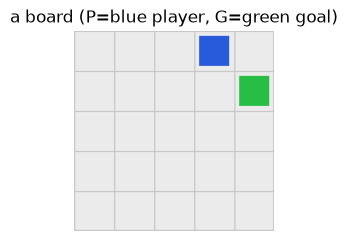

In [6]:
plt.figure(figsize=(2.6, 2.6))
plt.imshow(board['frame'])
plt.axis('off')
plt.title('a board (P=blue player, G=green goal)')
plt.show()

### Task

Reach the goal. Each policy plays the same 20 evaluation games, seeds 100 to 119, which were not used in training. A game ends when the goal is reached or the step limit runs out.

### Conditions

The four policies above: oracle (ceiling), random (floor), the pure clone, and the clone with the escape rule.

In [7]:
EVAL_SEEDS = range(100, 120)
EVAL_SIZE = 6

## Run

`play_game` runs one episode as a closed-loop session and returns its transcript: the moves taken, whether the goal was reached, and the shortest possible path. A fresh subject plays each game.

In [8]:
from brainscore.harnesses.grid_game import play_game

transcripts = {}                                 # policy name -> one transcript per game
for name, policy in POLICIES.items():
    transcripts[name] = []
    for seed in EVAL_SEEDS:
        subject = make_subject(policy)
        game = play_game(subject, GridGameEnv(size=EVAL_SIZE, seed=seed))
        transcripts[name].append(game)

## Read results back

One transcript per game; here the first three games of the pure clone.

In [9]:
pd.DataFrame(transcripts['neural, pure argmax'][:3])

,solved,steps,total_reward,optimal_steps,efficiency,actions
0,False,40,-0.40,5,0.000,"[1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, ..."
1,False,40,-0.40,2,0.000,"[0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, ..."
2,True,3,0.98,1,0.333,"[3, 0, 2]"


## Analysis

In [10]:
def success_rate(games):
    """Fraction of games solved."""
    return float(np.mean([1.0 if game['solved'] else 0.0 for game in games]))

def mean_efficiency(games):
    """Shortest path / steps taken, averaged over solved games only (0 if none were solved)."""
    solved = [game['efficiency'] for game in games if game['solved']]
    return float(np.mean(solved)) if solved else 0.0

## Results

In [11]:
summary = pd.DataFrame({name: {'success rate': success_rate(games), 'efficiency': mean_efficiency(games),
                               'games': len(games)} for name, games in transcripts.items()}).T
summary.round(2)

,success rate,efficiency,games
oracle (ceiling),1.00,1.00,20.0
random (floor),0.60,0.37,20.0
"neural, pure argmax",0.55,0.91,20.0
"neural, +escape",0.90,0.70,20.0


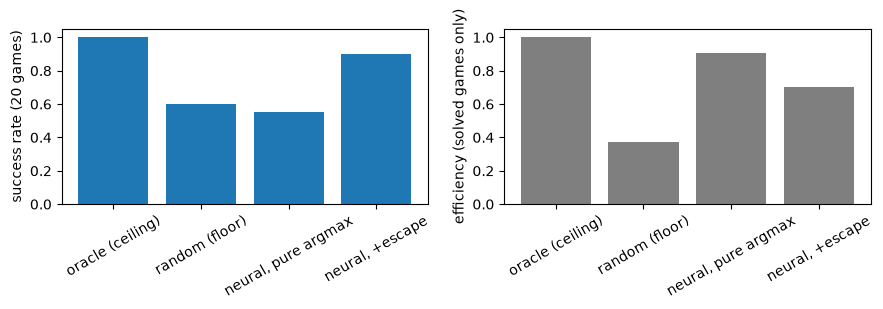

In [12]:
names = list(summary.index)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].bar(names, summary['success rate'], color='tab:blue')
ax[0].set_ylabel('success rate (20 games)')
ax[1].bar(names, summary['efficiency'], color='tab:gray')
ax[1].set_ylabel('efficiency (solved games only)')
for a in ax:
    a.set_ylim(0, 1.05)
    a.tick_params(axis='x', labelrotation=30)
fig.tight_layout()
plt.show()

The network matched the oracle on 96% of the 490 training frames. In the closed loop the pure clone solved 11 of 20 games (0.55), and the random policy solved 12 of 20 (0.60). The oracle solved 20 of 20.

On the games it did solve, the pure clone took near-optimal paths (efficiency 0.91, against 0.37 for random). With the cycle-escape rule added, the clone solved 18 of 20 games (0.90) at efficiency 0.70.

## Conclusion and limits

The hypothesis is not supported for the pure clone: high agreement with the expert on training frames did not produce a higher success rate than random moves on unseen games. When the pure clone solved a game it did so efficiently, which is consistent with failures coming from the deterministic policy repeating states rather than from choosing poor moves in general. Adding a random move on repeated states raised success to 18 of 20, which supports that reading: the pure-clone transcripts above show it alternating between two moves until the step limit. Three transcripts illustrate the failure; they do not measure how often it happens.

Limits:

- Twenty games per policy is a small sample. A difference of one game (11 vs. 12) is not evidence of a ranking.
- Training used 5 x 5 boards and evaluation used 6 x 6 boards, so the test mixes new states with a new board size.
- The environment is a synthetic grid game. The result says nothing about robotic or biological agents.
- Each policy is evaluated with one training seed. More seeds are needed before treating any of these numbers as stable.